In [2]:
import os, copy, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Using device: cuda


In [3]:
IMG_SIZE      = 128
BATCH_SIZE    = 32
EPOCHS        = 30
LR            = 1e-3
DROPOUT_P     = 0.5
TRAIN_RATIO, VAL_RATIO, TEST_RATIO = 0.70, 0.15, 0.15

IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp")
DATA_ROOT = None    

def has_images(folder):
    for _, _, files in os.walk(folder):
        if any(f.lower().endswith(IMG_EXT) for f in files):
            return True
    return False

def find_dataset_root(search_root="/kaggle/input"):
    """Shallowest folder whose sub-folders (>=2) are the class folders holding the images."""
    for current, subdirs, files in os.walk(search_root):
        class_dirs = [d for d in subdirs if has_images(os.path.join(current, d))]
        if len(class_dirs) >= 2:
            return current
    return None

data_root = DATA_ROOT if DATA_ROOT else find_dataset_root()
print("Dataset root:", data_root)
print("Folders inside:", sorted(os.listdir(data_root)))

Dataset root: /kaggle/input/datasets/mushfikarahman15/fig-leaves-dataset/fig leaves dataset/Fig Leaves Dataset
Folders inside: ['healthy', 'infected']


Number of classes : 2
Class names       : ['healthy', 'infected']
Total images      : 2321

Images per class:
healthy      971
infected    1350


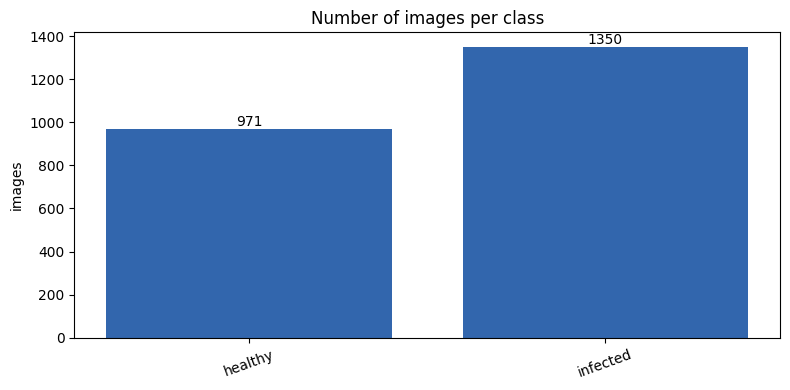

In [4]:
full_ds = datasets.ImageFolder(data_root)          
class_names = full_ds.classes
num_classes = len(class_names)
targets = np.array(full_ds.targets)

print("Number of classes :", num_classes)
print("Class names       :", class_names)
print("Total images      :", len(full_ds))

class_counts = pd.Series(np.bincount(targets), index=class_names, name="images")
print("\nImages per class:")
print(class_counts.to_string())

plt.figure(figsize=(8, 4))
bars = plt.bar(class_names, class_counts.values, color="#3266ad")
for b, v in zip(bars, class_counts.values):
    plt.text(b.get_x() + b.get_width()/2, v, str(v), ha="center", va="bottom")
plt.title("Number of images per class")
plt.ylabel("images"); plt.xticks(rotation=20)
plt.tight_layout(); plt.savefig("class_distribution.png", dpi=150); plt.show()

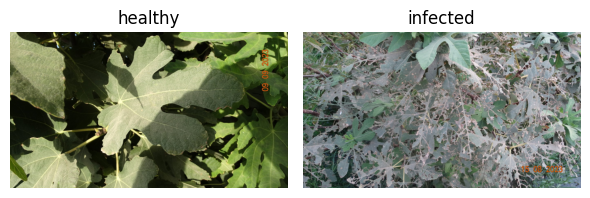

In [5]:

plt.figure(figsize=(3*num_classes, 3.2))
for c in range(num_classes):
    idx = int(np.where(targets == c)[0][0])
    img = full_ds[idx][0]
    plt.subplot(1, num_classes, c + 1)
    plt.imshow(img); plt.title(class_names[c]); plt.axis("off")
plt.tight_layout(); plt.show()

In [6]:
all_idx = np.arange(len(full_ds))
train_idx, temp_idx = train_test_split(
    all_idx, test_size=(1 - TRAIN_RATIO), stratify=targets, random_state=SEED)
val_idx, test_idx = train_test_split(
    temp_idx, test_size=TEST_RATIO / (VAL_RATIO + TEST_RATIO),
    stratify=targets[temp_idx], random_state=SEED)

print(f"Total images      : {len(all_idx)}")
print(f"Training images   : {len(train_idx)}")
print(f"Validation images : {len(val_idx)}")
print(f"Testing images    : {len(test_idx)}")

split_table = pd.DataFrame({
    "train": np.bincount(targets[train_idx], minlength=num_classes),
    "validation": np.bincount(targets[val_idx], minlength=num_classes),
    "test": np.bincount(targets[test_idx], minlength=num_classes),
}, index=class_names)
split_table["total"] = split_table.sum(axis=1)
split_table.loc["TOTAL"] = split_table.sum()
print("\nImages per class in each split:")
print(split_table.to_string())

Total images      : 2321
Training images   : 1624
Validation images : 348
Testing images    : 349

Images per class in each split:
          train  validation  test  total
healthy     679         146   146    971
infected    945         202   203   1350
TOTAL      1624         348   349   2321


In [7]:

basic_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
])


aug_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
])


ds_basic = datasets.ImageFolder(data_root, transform=basic_transform)
ds_aug   = datasets.ImageFolder(data_root, transform=aug_transform)

def make_loaders(use_aug):
    train_set = Subset(ds_aug if use_aug else ds_basic, train_idx)
    val_set   = Subset(ds_basic, val_idx)       
    test_set  = Subset(ds_basic, test_idx)      
    train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
    val_loader   = DataLoader(val_set,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
    test_loader  = DataLoader(test_set,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
    return train_loader, val_loader, test_loader

loaders_plain = make_loaders(use_aug=False)
loaders_aug   = make_loaders(use_aug=True)
print("Loaders ready.")

Loaders ready.


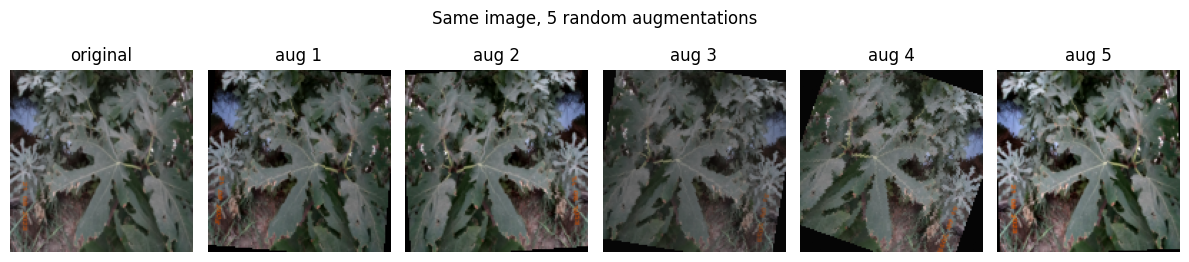

In [8]:

sample_i = int(train_idx[0])
plt.figure(figsize=(12, 2.8))
plt.subplot(1, 6, 1)
plt.imshow(ds_basic[sample_i][0].permute(1, 2, 0)); plt.title("original"); plt.axis("off")
for i in range(5):
    plt.subplot(1, 6, i + 2)
    plt.imshow(ds_aug[sample_i][0].permute(1, 2, 0)); plt.title(f"aug {i+1}"); plt.axis("off")
plt.suptitle("Same image, 5 random augmentations")
plt.tight_layout(); plt.show()

In [9]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes, p_dropout=0.0):
        super().__init__()
        
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)    
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)   
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)   
        self.pool = nn.MaxPool2d(2, 2)
        
        self.dropout = nn.Dropout(p_dropout)                       
        self.fc1 = nn.Linear(64 * (IMG_SIZE // 8) * (IMG_SIZE // 8), 128)
        self.fc2 = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

m = SimpleCNN(num_classes, DROPOUT_P).to(device)
print(m)
print(f"\nTotal trainable parameters: {sum(p.numel() for p in m.parameters()):,}")
del m

SimpleCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc1): Linear(in_features=16384, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=2, bias=True)
)

Total trainable parameters: 2,121,122


In [11]:
def run_epoch(model, loader, criterion, optimizer=None):
    """Train for one epoch if optimizer is given, otherwise evaluate."""
    is_train = optimizer is not None
    model.train() if is_train else model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(is_train):
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            if is_train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * imgs.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return total_loss / total, correct / total


def train_model(name, p_dropout, use_aug, epochs=EPOCHS, lr=LR):
    print(f"\n{'='*70}\nExperiment: {name}  (dropout={p_dropout}, augmentation={use_aug})\n{'='*70}")
    torch.manual_seed(SEED)                     
    train_loader, val_loader, test_loader = loaders_aug if use_aug else loaders_plain

    model = SimpleCNN(num_classes, p_dropout).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_loss, best_epoch, best_state = float("inf"), 0, None

    for ep in range(1, epochs + 1):
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer)
        va_loss, va_acc = run_epoch(model, val_loader, criterion)

        history["train_loss"].append(tr_loss); history["train_acc"].append(tr_acc)
        history["val_loss"].append(va_loss);   history["val_acc"].append(va_acc)

        if va_loss < best_val_loss:              
            best_val_loss, best_epoch = va_loss, ep
            best_state = copy.deepcopy(model.state_dict())

        print(f"Epoch {ep:2d}/{epochs} | train_loss={tr_loss:.4f} train_acc={tr_acc:.4f} | "
              f"val_loss={va_loss:.4f} val_acc={va_acc:.4f}")

    
    model.load_state_dict(best_state)
    test_loss, test_acc = run_epoch(model, test_loader, criterion)
    print(f"\nBest epoch (lowest val loss): {best_epoch}")
    print(f"Test loss: {test_loss:.4f} | Test accuracy: {test_acc:.4f}")

    return model, history, {"best_epoch": best_epoch, "test_loss": test_loss, "test_acc": test_acc}

In [14]:
def plot_history(history, title, filename=None):
    ep = range(1, len(history["train_loss"]) + 1)
    best_ep = int(np.argmin(history["val_loss"])) + 1
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

    ax1.plot(ep, history["train_loss"], "o-", ms=3, label="train")
    ax1.plot(ep, history["val_loss"],   "o-", ms=3, label="validation")
    ax1.axvline(best_ep, color="gray", ls="--", lw=1, label=f"best val loss (epoch {best_ep})")
    ax1.set_title("Loss (lower = better)"); ax1.set_xlabel("epoch"); ax1.set_ylabel("loss")
    ax1.legend(); ax1.grid(True)

    ax2.plot(ep, history["train_acc"], "o-", ms=3, label="train")
    ax2.plot(ep, history["val_acc"],   "o-", ms=3, label="validation")
    ax2.axvline(best_ep, color="gray", ls="--", lw=1)
    ax2.set_title("Accuracy (higher = better)"); ax2.set_xlabel("epoch"); ax2.set_ylabel("accuracy")
    ax2.legend(); ax2.grid(True)

    fig.suptitle(title, fontsize=13)
    plt.tight_layout()
    if filename: plt.savefig(filename, dpi=150, bbox_inches="tight")
    plt.show()


Experiment: Baseline  (dropout=0.0, augmentation=False)
Epoch  1/30 | train_loss=0.6896 train_acc=0.5450 | val_loss=0.6774 val_acc=0.5805
Epoch  2/30 | train_loss=0.6804 train_acc=0.5917 | val_loss=0.6730 val_acc=0.5805
Epoch  3/30 | train_loss=0.6513 train_acc=0.6084 | val_loss=0.5839 val_acc=0.6983
Epoch  4/30 | train_loss=0.4817 train_acc=0.7833 | val_loss=0.5375 val_acc=0.7040
Epoch  5/30 | train_loss=0.4138 train_acc=0.8140 | val_loss=0.4183 val_acc=0.8017
Epoch  6/30 | train_loss=0.3795 train_acc=0.8190 | val_loss=0.3593 val_acc=0.8391
Epoch  7/30 | train_loss=0.2901 train_acc=0.8645 | val_loss=0.3043 val_acc=0.8793
Epoch  8/30 | train_loss=0.2677 train_acc=0.8898 | val_loss=0.3224 val_acc=0.8879
Epoch  9/30 | train_loss=0.2343 train_acc=0.9064 | val_loss=0.3805 val_acc=0.8420
Epoch 10/30 | train_loss=0.2122 train_acc=0.9138 | val_loss=0.3320 val_acc=0.8649
Epoch 11/30 | train_loss=0.1842 train_acc=0.9261 | val_loss=0.3119 val_acc=0.8707
Epoch 12/30 | train_loss=0.1727 train_acc

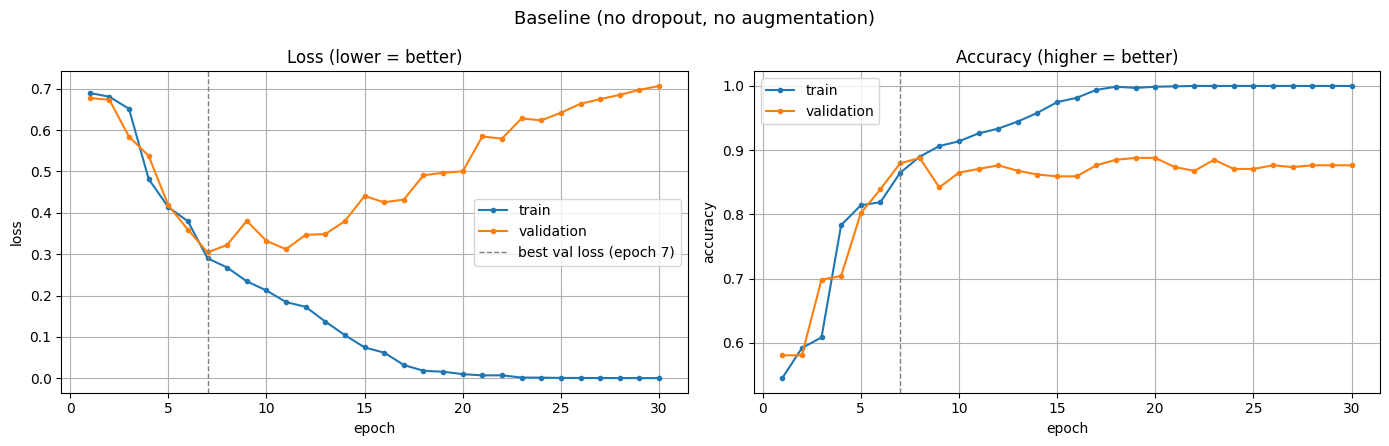

In [15]:
model_base, hist_base, res_base = train_model("Baseline", p_dropout=0.0, use_aug=False)
plot_history(hist_base, "Baseline (no dropout, no augmentation)", "curves_baseline.png")


Experiment: Dropout + Augmentation  (dropout=0.5, augmentation=True)
Epoch  1/30 | train_loss=0.6858 train_acc=0.5554 | val_loss=0.6770 val_acc=0.5805
Epoch  2/30 | train_loss=0.6795 train_acc=0.5831 | val_loss=0.6924 val_acc=0.5805
Epoch  3/30 | train_loss=0.6599 train_acc=0.6127 | val_loss=0.6553 val_acc=0.5833
Epoch  4/30 | train_loss=0.6371 train_acc=0.6613 | val_loss=0.6223 val_acc=0.7040
Epoch  5/30 | train_loss=0.5817 train_acc=0.7328 | val_loss=0.4924 val_acc=0.8017
Epoch  6/30 | train_loss=0.5395 train_acc=0.7469 | val_loss=0.5039 val_acc=0.7414
Epoch  7/30 | train_loss=0.4926 train_acc=0.7679 | val_loss=0.5053 val_acc=0.7931
Epoch  8/30 | train_loss=0.5146 train_acc=0.7617 | val_loss=0.4365 val_acc=0.8075
Epoch  9/30 | train_loss=0.5029 train_acc=0.7796 | val_loss=0.4619 val_acc=0.7816
Epoch 10/30 | train_loss=0.4609 train_acc=0.7968 | val_loss=0.4177 val_acc=0.8333
Epoch 11/30 | train_loss=0.4699 train_acc=0.7851 | val_loss=0.4429 val_acc=0.8132
Epoch 12/30 | train_loss=0.4

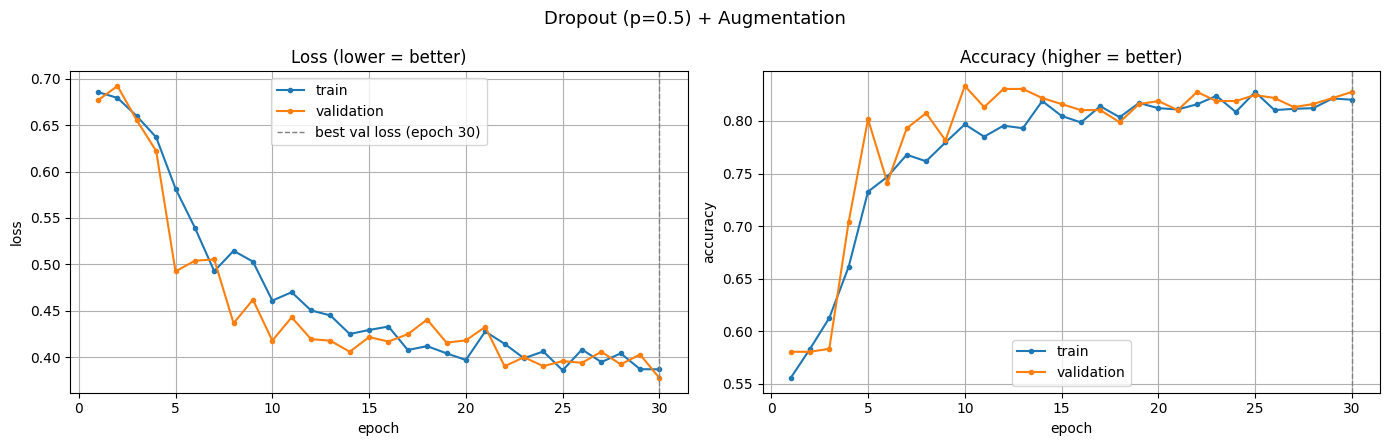

In [16]:
model_both, hist_both, res_both = train_model("Dropout + Augmentation", p_dropout=DROPOUT_P, use_aug=True)
plot_history(hist_both, f"Dropout (p={DROPOUT_P}) + Augmentation", "curves_dropout_augmentation.png")

In [20]:
experiments = {
    "Baseline":               (hist_base, res_base),
    "Dropout + Augmentation": (hist_both, res_both),
}

rows = []
for name, (h, r) in experiments.items():
    rows.append({
        "Experiment": name,
        "Best val loss":  round(min(h["val_loss"]), 4),
        "Best val acc":   round(max(h["val_acc"]), 4),
        "Best epoch (val loss)": r["best_epoch"],
        "Final train acc": round(h["train_acc"][-1], 4),
        "Final val acc":   round(h["val_acc"][-1], 4),
        "Train-Val acc gap (final)": round(h["train_acc"][-1] - h["val_acc"][-1], 4),
        "Test loss": round(r["test_loss"], 4),
        "Test acc":  round(r["test_acc"], 4),
    })
summary = pd.DataFrame(rows).set_index("Experiment")
summary.to_csv("results_summary.csv")
summary

,Best val loss,Best val acc,Best epoch (val loss),Final train acc,Final val acc,Train-Val acc gap (final),Test loss,Test acc
Experiment,,,,,,,,
Baseline,0.3043,0.8879,7,1.0000,0.8764,0.1236,0.3400,0.8424
Dropout + Augmentation,0.3773,0.8333,30,0.8202,0.8276,-0.0074,0.3773,0.8223


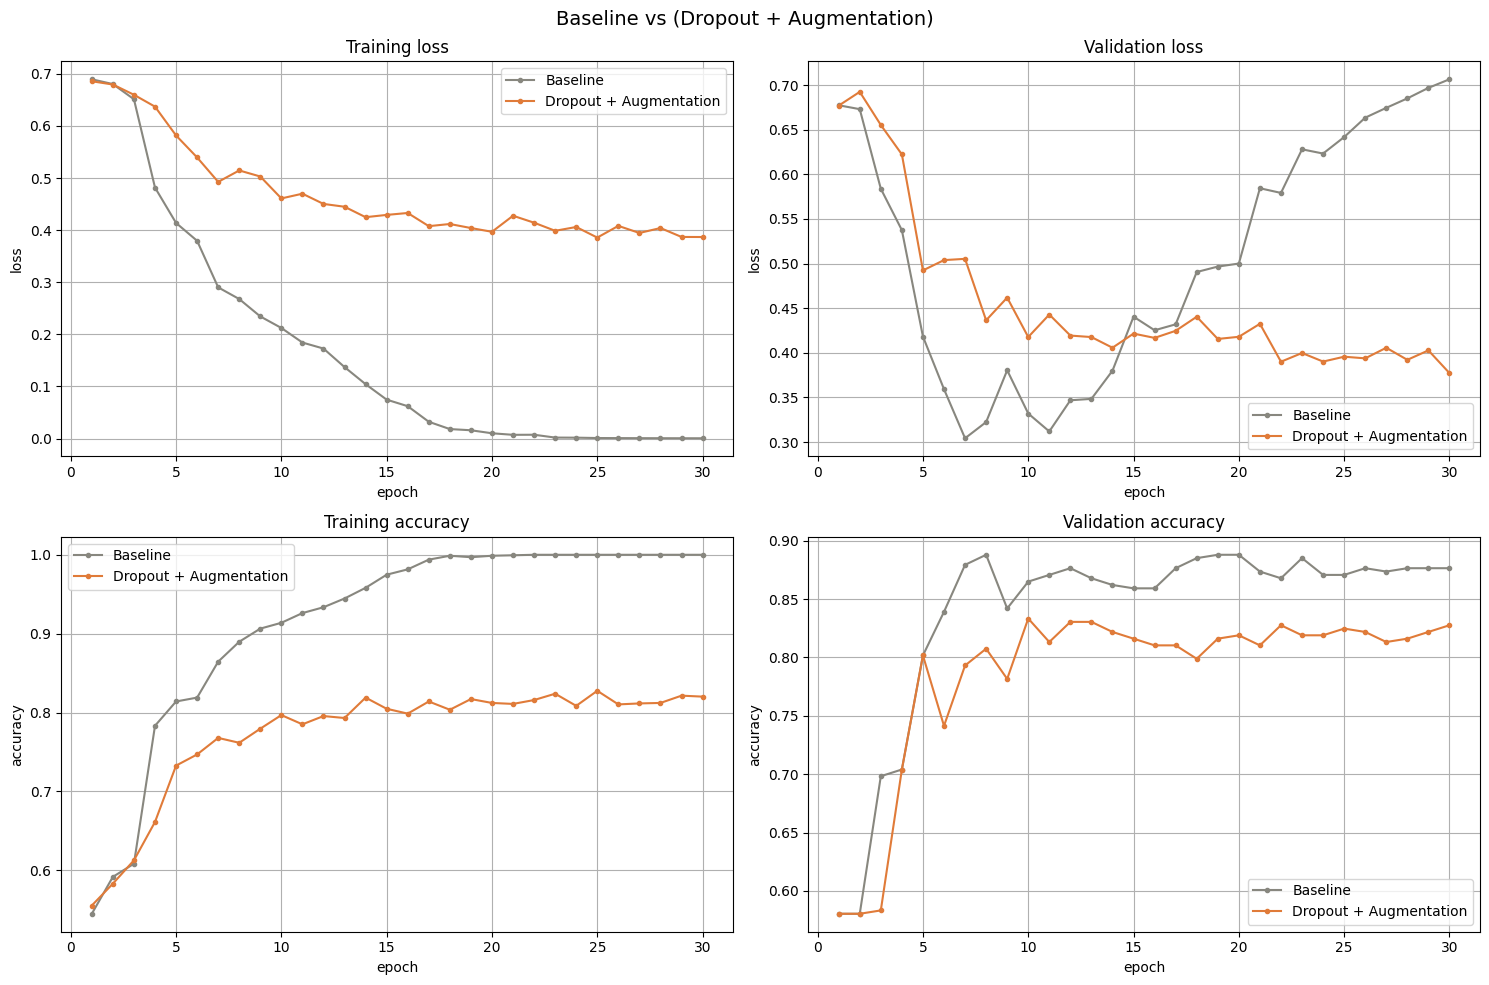

In [26]:

ep = range(1, EPOCHS + 1)
colors = {"Baseline": "#88877f","Dropout + Augmentation": "#e07b39"}

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
panels = [("train_loss", "Training loss"),   ("val_loss", "Validation loss"),
          ("train_acc",  "Training accuracy"), ("val_acc",  "Validation accuracy")]

for ax, (key, title) in zip(axes.flatten(), panels):
    for name, (h, _) in experiments.items():
        ax.plot(ep, h[key], "o-", ms=3, color=colors[name], label=name)
    ax.set_title(title); ax.set_xlabel("epoch")
    ax.set_ylabel("loss" if "loss" in key else "accuracy")
    ax.grid(True); ax.legend()

fig.suptitle("Baseline vs (Dropout + Augmentation)", fontsize=14)
plt.tight_layout()
plt.savefig("curves_comparison_all.png", dpi=150, bbox_inches="tight")
plt.show()

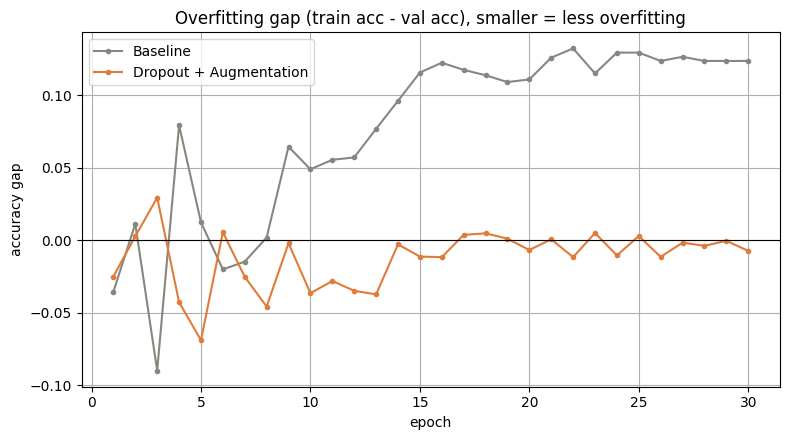

In [27]:

plt.figure(figsize=(8, 4.5))
for name, (h, _) in experiments.items():
    gap = np.array(h["train_acc"]) - np.array(h["val_acc"])
    plt.plot(ep, gap, "o-", ms=3, color=colors[name], label=name)
plt.axhline(0, color="black", lw=0.8)
plt.title("Overfitting gap (train acc - val acc), smaller = less overfitting")
plt.xlabel("epoch"); plt.ylabel("accuracy gap"); plt.grid(True); plt.legend()
plt.tight_layout(); plt.savefig("overfitting_gap.png", dpi=150); plt.show()

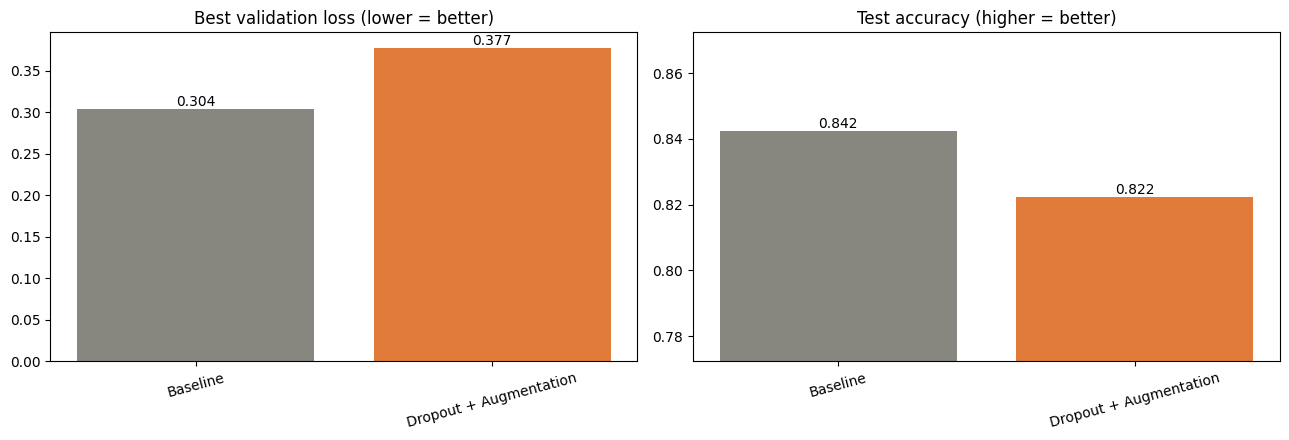

In [28]:

names = list(experiments.keys())
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

vals = [min(experiments[n][0]["val_loss"]) for n in names]
ax1.bar(names, vals, color=[colors[n] for n in names])
for i, v in enumerate(vals): ax1.text(i, v, f"{v:.3f}", ha="center", va="bottom")
ax1.set_title("Best validation loss (lower = better)"); ax1.tick_params(axis="x", rotation=15)

vals = [experiments[n][1]["test_acc"] for n in names]
ax2.bar(names, vals, color=[colors[n] for n in names])
for i, v in enumerate(vals): ax2.text(i, v, f"{v:.3f}", ha="center", va="bottom")
ax2.set_title("Test accuracy (higher = better)"); ax2.tick_params(axis="x", rotation=15)
ax2.set_ylim(min(vals) - 0.05, min(1.0, max(vals) + 0.03))

plt.tight_layout(); plt.savefig("bar_comparison.png", dpi=150); plt.show()

In [30]:
best_name = summary["Best val loss"].idxmin()
base = summary.loc["Baseline"]

print("=" * 70)
print("DATASET SUMMARY")
print("=" * 70)
print(f"Number of classes     : {num_classes}  {class_names}")
print(f"Total images          : {len(full_ds)}")
print(f"Training images       : {len(train_idx)}")
print(f"Validation images     : {len(val_idx)}")
print(f"Testing images        : {len(test_idx)}")
print(f"Epochs per experiment : {EPOCHS}")
print()
print("=" * 70)
print("RESULTS (best loss and accuracy)")
print("=" * 70)
print(summary.to_string())
print()
print(f"Best experiment (lowest validation loss): {best_name}")
for name in summary.index:
    if name == "Baseline": continue
    r = summary.loc[name]
    print(f"{name:24s} vs Baseline -> "
          f"val loss {r['Best val loss'] - base['Best val loss']:+.4f}, "
          f"val acc {r['Best val acc'] - base['Best val acc']:+.4f}, "
          f"test acc {r['Test acc'] - base['Test acc']:+.4f}")

DATASET SUMMARY
Number of classes     : 2  ['healthy', 'infected']
Total images          : 2321
Training images       : 1624
Validation images     : 348
Testing images        : 349
Epochs per experiment : 30

RESULTS (best loss and accuracy)
                        Best val loss  Best val acc  Best epoch (val loss)  Final train acc  Final val acc  Train-Val acc gap (final)  Test loss  Test acc
Experiment                                                                                                                                                
Baseline                       0.3043        0.8879                      7           1.0000         0.8764                     0.1236     0.3400    0.8424
Dropout + Augmentation         0.3773        0.8333                     30           0.8202         0.8276                    -0.0074     0.3773    0.8223

Best experiment (lowest validation loss): Baseline
Dropout + Augmentation   vs Baseline -> val loss +0.0730, val acc -0.0546, test acc -0